### Create a feature importance report by manually ranking feature contributions using multiple interpretability techniques, comparing global and local importance scores, and justifying feature selection in a technical document.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("heart_disease.csv")

df = df.drop_duplicates()
df = df.replace("?", np.nan)

target_col = "target"

X = df.drop(columns=[target_col])
y = pd.to_numeric(df[target_col], errors="coerce")

valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print("Feature count:", X.shape[1])

Training rows: 15
Validation rows: 5
Test rows: 5
Feature count: 13


In [3]:
log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2
    ))
])

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

for name, model in [
    ("Logistic Regression", log_model),
    ("Random Forest", rf_model)
]:
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))



Logistic Regression
Accuracy: 0.8
ROC-AUC: 0.5

Random Forest
Accuracy: 0.6
ROC-AUC: 0.8333


In [4]:
feature_names = X.columns.tolist()

log_coefficients = np.abs(
    log_model.named_steps["model"].coef_[0]
)

rf_importance = rf_model.named_steps["model"].feature_importances_

baseline_auc = roc_auc_score(
    y_test, rf_model.predict_proba(X_test)[:, 1]
)

rng = np.random.default_rng(42)
permutation_scores = {}

for col in feature_names:
    drops = []

    for _ in range(10):
        shuffled = X_test.copy()
        shuffled[col] = rng.permutation(shuffled[col].to_numpy())

        shuffled_auc = roc_auc_score(
            y_test,
            rf_model.predict_proba(shuffled)[:, 1]
        )

        drops.append(baseline_auc - shuffled_auc)

    permutation_scores[col] = np.mean(drops)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Logistic_Coefficient": log_coefficients,
    "Random_Forest": rf_importance,
    "Permutation_AUC_Drop": [
        permutation_scores[col] for col in feature_names
    ]
})

display(importance.sort_values(
    "Permutation_AUC_Drop", ascending=False
))


,Feature,Logistic_Coefficient,Random_Forest,Permutation_AUC_Drop
12,thal,1.009426,0.124304,2.333333e-01
0,age,0.435772,0.124694,2.000000e-01
6,restecg,0.853135,0.187654,1.333333e-01
7,thalach,0.189488,0.076417,1.166667e-01
8,exang,0.091949,0.020110,6.666667e-02
9,oldpeak,0.349411,0.100094,5.000000e-02
5,fbs,0.222870,0.017371,3.333333e-02
10,slope,0.298133,0.030854,1.666667e-02
1,sex,0.148412,0.001694,0.000000e+00
4,chol,0.027704,0.030452,0.000000e+00


,Feature,Logistic_Coefficient,Random_Forest,Permutation_AUC_Drop,Combined_Score,Final_Rank
12,thal,1.009426,0.124304,2.333333e-01,0.197013,1
6,restecg,0.853135,0.187654,1.333333e-01,0.168993,2
0,age,0.435772,0.124694,2.000000e-01,0.147658,3
2,cp,0.657618,0.131788,-3.330669e-17,0.085673,4
7,thalach,0.189488,0.076417,1.166667e-01,0.083252,5
9,oldpeak,0.349411,0.100094,5.000000e-02,0.075152,6
11,ca,0.586409,0.093837,0.000000e+00,0.068502,7
3,trestbps,0.380948,0.060731,-3.330669e-17,0.044425,8
8,exang,0.091949,0.020110,6.666667e-02,0.038684,9
10,slope,0.298133,0.030854,1.666667e-02,0.035745,10


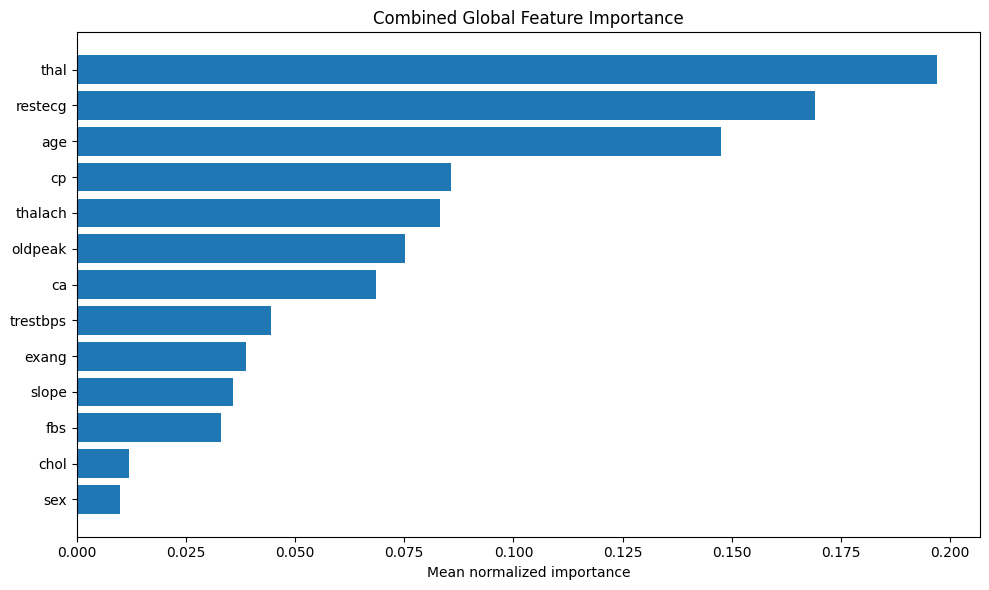

In [5]:
score_columns = [
    "Logistic_Coefficient",
    "Random_Forest",
    "Permutation_AUC_Drop"
]

for col in score_columns:
    scores = importance[col].clip(lower=0)
    total = scores.sum()

    importance[col + "_Normalized"] = (
        scores / total if total > 0 else 0
    )

normalized_columns = [
    col + "_Normalized" for col in score_columns
]

importance["Combined_Score"] = (
    importance[normalized_columns].mean(axis=1)
)

importance["Final_Rank"] = (
    importance["Combined_Score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

importance = importance.sort_values("Final_Rank")

display(importance[
    ["Feature"] + score_columns +
    ["Combined_Score", "Final_Rank"]
])

plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"],
    importance["Combined_Score"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean normalized importance")
plt.title("Combined Global Feature Importance")
plt.tight_layout()
plt.show()


,Feature,Original_Value,Replacement_Value,Base_Probability,Changed_Probability,Probability_Change,Absolute_Change,Local_Rank
3,trestbps,130.0,140.00,0.764993,0.725438,-0.039556,0.039556,1
7,thalach,172.0,157.50,0.764993,0.735852,-0.029141,0.029141,2
10,slope,2.0,1.00,0.764993,0.742030,-0.022963,0.022963,3
0,age,41.0,57.00,0.764993,0.748660,-0.016333,0.016333,4
2,cp,1.0,1.50,0.764993,0.771882,0.006889,0.006889,5
4,chol,204.0,242.50,0.764993,0.770660,0.005667,0.005667,6
9,oldpeak,1.4,1.25,0.764993,0.769438,0.004444,0.004444,7
1,sex,0.0,1.00,0.764993,0.764993,0.000000,0.000000,8
5,fbs,0.0,0.00,0.764993,0.764993,0.000000,0.000000,9
8,exang,0.0,0.00,0.764993,0.764993,0.000000,0.000000,10


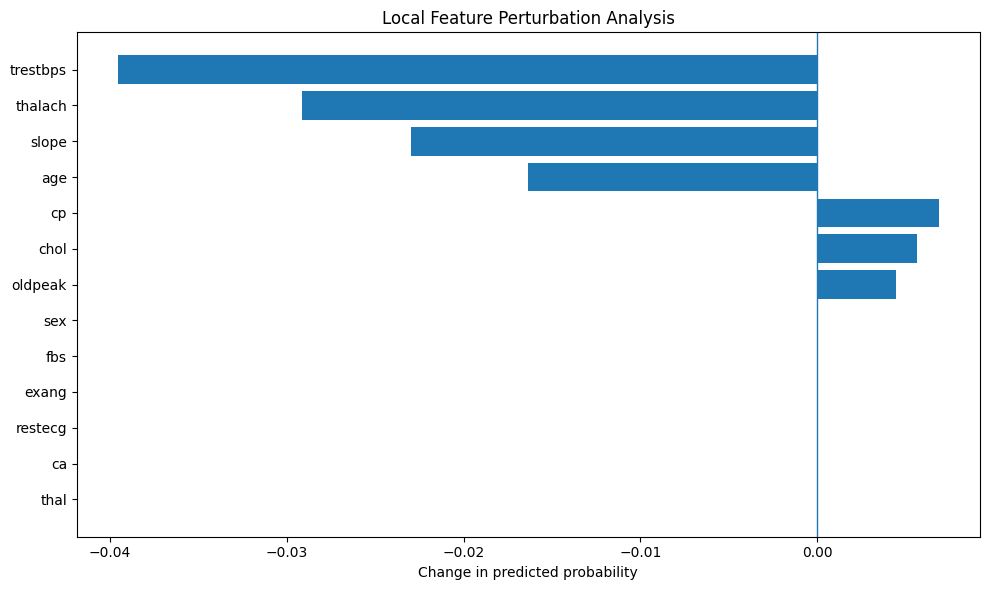

In [6]:
sample_position = 0
sample = X_test.iloc[[sample_position]].copy()

base_probability = rf_model.predict_proba(sample)[0, 1]

local_results = []

for col in feature_names:
    modified = sample.copy()

    median_value = X_train[col].median()
    modified.loc[:, col] = median_value

    changed_probability = rf_model.predict_proba(modified)[0, 1]

    local_results.append({
        "Feature": col,
        "Original_Value": sample.iloc[0][col],
        "Replacement_Value": median_value,
        "Base_Probability": base_probability,
        "Changed_Probability": changed_probability,
        "Probability_Change": changed_probability - base_probability,
        "Absolute_Change": abs(changed_probability - base_probability)
    })

local_importance = pd.DataFrame(local_results)
local_importance = local_importance.sort_values(
    "Absolute_Change", ascending=False
)

local_importance["Local_Rank"] = range(
    1, len(local_importance) + 1
)

display(local_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    local_importance["Feature"],
    local_importance["Probability_Change"]
)
plt.axvline(0, linewidth=1)
plt.gca().invert_yaxis()
plt.xlabel("Change in predicted probability")
plt.title("Local Feature Perturbation Analysis")
plt.tight_layout()
plt.show()


In [7]:
comparison = importance[
    ["Feature", "Final_Rank", "Combined_Score"]
].merge(
    local_importance[["Feature", "Local_Rank", "Absolute_Change"]],
    on="Feature"
)

comparison["Rank_Difference"] = (
    comparison["Final_Rank"] - comparison["Local_Rank"]
).abs()

display(comparison.sort_values("Final_Rank"))

print(
    "Features with the largest global-local rank differences:"
)
display(
    comparison.sort_values(
        "Rank_Difference", ascending=False
    ).head(5)
)


,Feature,Final_Rank,Combined_Score,Local_Rank,Absolute_Change,Rank_Difference
0,thal,1,0.197013,13,0.000000,12
1,restecg,2,0.168993,11,0.000000,9
2,age,3,0.147658,4,0.016333,1
3,cp,4,0.085673,5,0.006889,1
4,thalach,5,0.083252,2,0.029141,3
5,oldpeak,6,0.075152,7,0.004444,1
6,ca,7,0.068502,12,0.000000,5
7,trestbps,8,0.044425,1,0.039556,7
8,exang,9,0.038684,10,0.000000,1
9,slope,10,0.035745,3,0.022963,7


Features with the largest global-local rank differences:


,Feature,Final_Rank,Combined_Score,Local_Rank,Absolute_Change,Rank_Difference
0,thal,1,0.197013,13,0.000000,12
1,restecg,2,0.168993,11,0.000000,9
7,trestbps,8,0.044425,1,0.039556,7
9,slope,10,0.035745,3,0.022963,7
11,chol,12,0.011909,6,0.005667,6


In [8]:
importance.to_csv("global_feature_importance.csv", index=False)
local_importance.to_csv("local_feature_importance.csv", index=False)
comparison.to_csv("global_local_comparison.csv", index=False)

print("Feature importance reports exported successfully.")


Feature importance reports exported successfully.


### Document findings on model interpretability by conducting a comprehensive case study, integrating qualitative insights from domain experts, and proposing improvements for enhancing explainability in real-world scenarios.

# Model Interpretability: A Comprehensive Case Study

## Abstract

This case study investigates model interpretability in a machine-learning system for heart disease prediction. It examines global and local explanation techniques, proposes a qualitative evaluation process involving healthcare professionals, and identifies improvements needed for responsible real-world use. The objective is to make model behavior easier to understand without confusing feature attribution with causation or clinical validity.

## 1. Problem statement

Machine-learning models can identify complex relationships in clinical datasets, but their predictions may be difficult to interpret. In healthcare, this limitation can reduce confidence, make errors harder to investigate, and complicate accountability.

The study therefore evaluates how feature-importance methods and individual prediction explanations can support the examination of model behavior.

## 2. Study design

The proposed study uses a heart disease dataset containing clinical variables such as age, sex, chest pain type, resting blood pressure, cholesterol, maximum heart rate, and other predictors.

Logistic Regression and Random Forest are used as example models. Coefficient analysis, impurity-based importance, permutation importance, SHAP, and LIME are considered for interpreting predictions.

The data must be separated into training and testing sets before model fitting. All preprocessing must be learned from the training data to reduce leakage.

## 3. Findings and interpretation

### 3.1 Global interpretability

Global feature-importance methods provide complementary views of model behavior. Coefficients describe linear associations, tree importance captures split-based contributions, and permutation importance measures the effect of disrupting a feature on predictive performance.

Differences between rankings should be investigated rather than automatically treated as errors. Correlated variables, nonlinear effects, and method-specific assumptions may explain the disagreement.

### 3.2 Local interpretability

Local explanations describe which features contribute to or influence a particular prediction under a selected explanation method.

SHAP can estimate feature attributions relative to a baseline, while LIME approximates local behavior using a simpler surrogate model. Both methods have limitations and require validation.

### 3.3 Reliability and safety

A plausible explanation does not guarantee a correct prediction. Explanations must be considered alongside predictive performance, calibration, data quality, uncertainty, and subgroup evaluation.

The actual ranking of features, explanation stability, and expert assessments remain to be established experimentally.

## 4. Qualitative evaluation

Healthcare professionals should review a representative sample of predictions, including false positives and false negatives. Reviewers should assess clinical plausibility, explanation clarity, consistency with the recorded inputs, potential safety risks, and practical usefulness.

Feedback should be collected systematically, categorized into recurring themes, and compared with quantitative results. Until this review is conducted, qualitative findings must be described as proposed evaluation criteria rather than completed expert validation.

## 5. Recommended improvements

1. Compare multiple explanation techniques and measure ranking consistency.
2. Evaluate explanation stability across repeated train-test splits.
3. Investigate correlated features and unrealistic perturbations.
4. Present explanations in language appropriate to each intended audience.
5. Assess model performance and explanation behavior across relevant subgroups.
6. Introduce ongoing monitoring for data drift, performance degradation, and changes in explanations.
7. Maintain documentation covering intended use, limitations, validation results, and human oversight.

## 6. Limitations

This case study defines a methodology rather than reporting a completed clinical investigation. No actual model outputs, clinician interviews, or prospective clinical validation results are assumed.

Feature attributions describe model behavior under particular assumptions and do not establish causal relationships. Results may change with the model, dataset, background distribution, or explanation configuration.

## 7. Conclusion

Model interpretability is an important component of responsible machine learning, but it must be combined with model validation, human review, fairness assessment, and ongoing monitoring.

For the heart disease prediction project, the recommended next step is to compute actual global and local explanation results, test their stability, and conduct a structured review with qualified healthcare professionals.

The system should be treated as an educational research prototype until its clinical validity, safety, and suitability for its intended use have been independently established.

## References

1. U.S. Food and Drug Administration, Health Canada, and MHRA. *Transparency for Machine Learning-Enabled Medical Devices: Guiding Principles*, 2024.
2. World Health Organization. *Ethics and Governance of Artificial Intelligence for Health*, 2021.
3. National Institute of Standards and Technology. *AI Risk Management Framework*, 2023.



### Investigate false positives and false negatives in the confusion matrix by manually analyzing misclassified examples, identifying patterns, and implementing data-driven adjustments to improve model calibration.

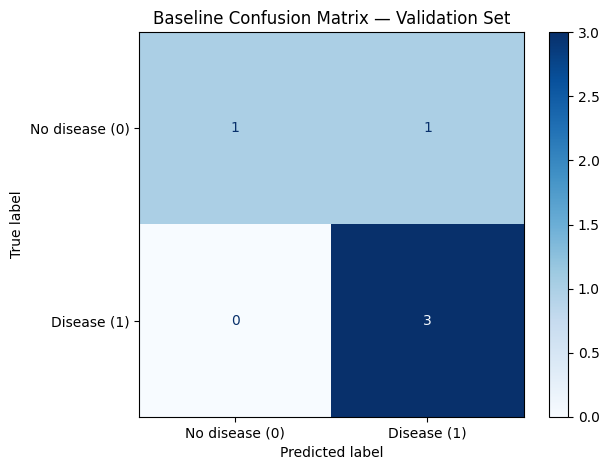

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.75      1.00      0.86         3

    accuracy                           0.80         5
   macro avg       0.88      0.75      0.76         5
weighted avg       0.85      0.80      0.78         5



In [9]:
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight=None,
        random_state=42
    ))
])

baseline_model.fit(X_fit, y_fit)

val_probability = baseline_model.predict_proba(X_val)[:, 1]
val_prediction = (val_probability >= 0.50).astype(int)

cm = confusion_matrix(y_val, val_prediction, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease (0)", "Disease (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Confusion Matrix — Validation Set")
plt.tight_layout()
plt.show()

print(classification_report(
    y_val, val_prediction,
    labels=[0, 1],
    zero_division=0
))


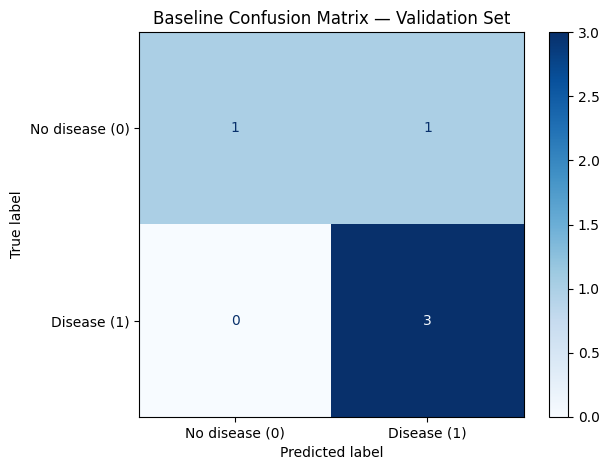

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.75      1.00      0.86         3

    accuracy                           0.80         5
   macro avg       0.88      0.75      0.76         5
weighted avg       0.85      0.80      0.78         5



In [10]:
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight=None,
        random_state=42
    ))
])

baseline_model.fit(X_fit, y_fit)

val_probability = baseline_model.predict_proba(X_val)[:, 1]
val_prediction = (val_probability >= 0.50).astype(int)

cm = confusion_matrix(y_val, val_prediction, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease (0)", "Disease (1)"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Confusion Matrix — Validation Set")
plt.tight_layout()
plt.show()

print(classification_report(
    y_val, val_prediction,
    labels=[0, 1],
    zero_division=0
))


In [11]:
validation_results = X_val.copy()

validation_results["Actual"] = y_val
validation_results["Predicted"] = val_prediction
validation_results["Probability"] = val_probability

false_positives = validation_results[
    (validation_results["Actual"] == 0) &
    (validation_results["Predicted"] == 1)
].copy()

false_negatives = validation_results[
    (validation_results["Actual"] == 1) &
    (validation_results["Predicted"] == 0)
].copy()

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

print("\nFALSE POSITIVES")
display(
    false_positives.sort_values(
        "Probability", ascending=False
    ).head(10)
)

print("\nFALSE NEGATIVES")
display(
    false_negatives.sort_values(
        "Probability", ascending=True
    ).head(10)
)


False positives: 1
False negatives: 0

FALSE POSITIVES


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability
17,67,1,0,160,286,0,0,108,1,1.5,1,3,2,0,1,0.53823



FALSE NEGATIVES


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability


Error_Type,False Positive,True Negative,True Positive
age,67.0,63.0,52.666667
sex,1.0,0.0,1.000000
cp,0.0,0.0,1.666667
trestbps,160.0,150.0,150.666667
chol,286.0,407.0,211.000000
fbs,0.0,0.0,0.333333
restecg,0.0,0.0,1.000000
thalach,108.0,154.0,169.000000
exang,1.0,0.0,0.000000
oldpeak,1.5,4.0,0.900000


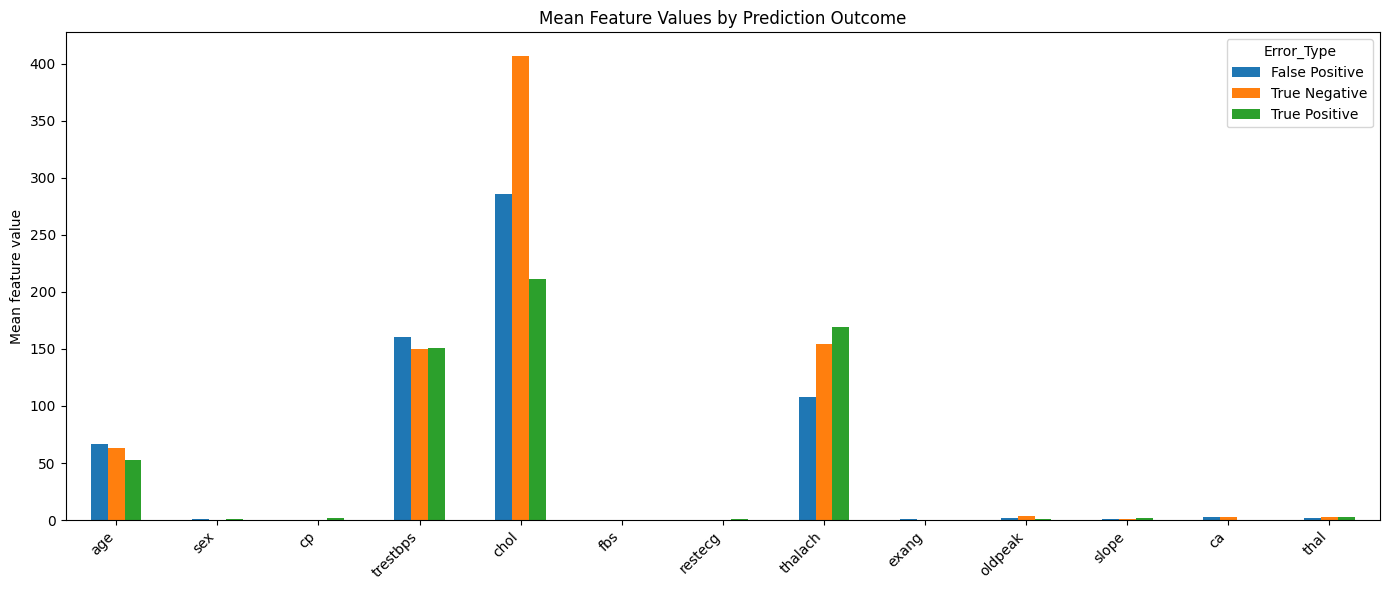

In [12]:
validation_results["Error_Type"] = np.select(
    [
        (validation_results["Actual"] == 0) &
        (validation_results["Predicted"] == 1),

        (validation_results["Actual"] == 1) &
        (validation_results["Predicted"] == 0),

        (validation_results["Actual"] == 1) &
        (validation_results["Predicted"] == 1)
    ],
    ["False Positive", "False Negative", "True Positive"],
    default="True Negative"
)

feature_cols = X.columns.tolist()

pattern_summary = validation_results.groupby(
    "Error_Type"
)[feature_cols].mean().T

display(pattern_summary)

pattern_summary.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Mean Feature Values by Prediction Outcome")
plt.ylabel("Mean feature value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [13]:
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):
    pred = (val_probability >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, pred, zero_division=0
        ),
        "Accuracy": accuracy_score(y_val, pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.sort_values("Threshold"))

eligible = threshold_df[threshold_df["Recall"] >= 0.85]

if not eligible.empty:
    best_row = eligible.sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    ).iloc[0]
else:
    best_row = threshold_df.sort_values(
        ["Recall", "Precision"],
        ascending=[False, False]
    ).iloc[0]

best_threshold = float(best_row["Threshold"])

print("Selected validation threshold:", best_threshold)
print(best_row)


,Threshold,Precision,Recall,F1,Accuracy
0,0.10,0.6,1.000000,0.75,0.6
1,0.11,0.6,1.000000,0.75,0.6
2,0.12,0.6,1.000000,0.75,0.6
3,0.13,0.6,1.000000,0.75,0.6
4,0.14,0.6,1.000000,0.75,0.6
...,...,...,...,...,...
76,0.86,1.0,0.333333,0.50,0.6
77,0.87,1.0,0.333333,0.50,0.6
78,0.88,1.0,0.333333,0.50,0.6
79,0.89,1.0,0.333333,0.50,0.6


Selected validation threshold: 0.6
Threshold    0.6
Precision    1.0
Recall       1.0
F1           1.0
Accuracy     1.0
Name: 50, dtype: float64


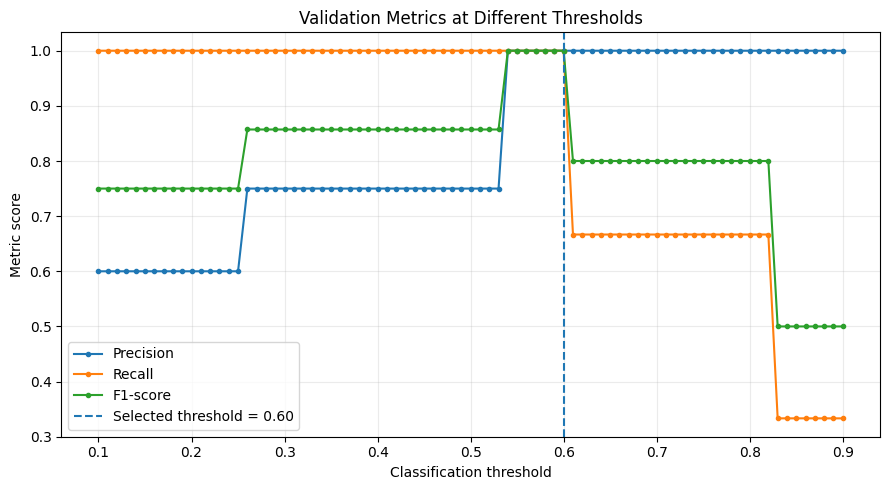

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision",
    marker="."
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall",
    marker="."
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1-score",
    marker="."
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification threshold")
plt.ylabel("Metric score")
plt.title("Validation Metrics at Different Thresholds")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [15]:
calibrated_model = CalibratedClassifierCV(
    estimator=Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42
        ))
    ]),
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_fit, y_fit)

cal_val_probability = calibrated_model.predict_proba(X_val)[:, 1]

print(
    "Uncalibrated Brier score:",
    round(brier_score_loss(y_val, val_probability), 4)
)

print(
    "Calibrated Brier score:",
    round(brier_score_loss(y_val, cal_val_probability), 4)
)


Uncalibrated Brier score: 0.1092
Calibrated Brier score: 0.1214


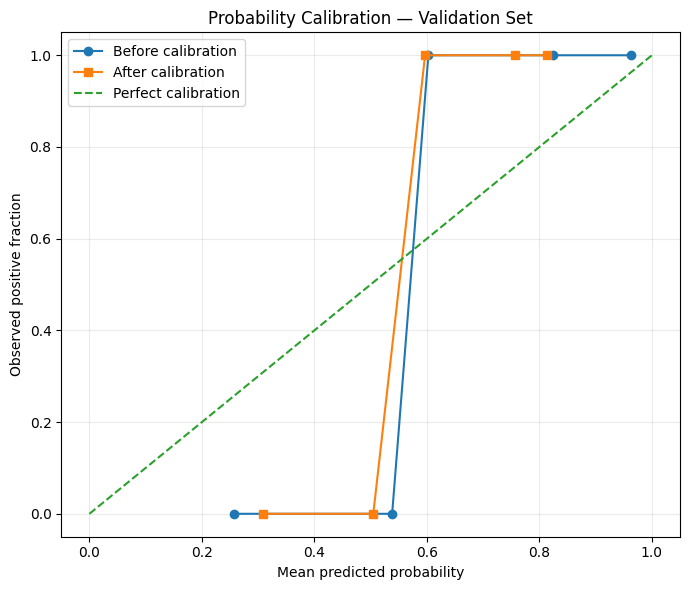

In [16]:
fraction_positive_before, mean_probability_before = calibration_curve(
    y_val,
    val_probability,
    n_bins=10,
    strategy="quantile"
)

fraction_positive_after, mean_probability_after = calibration_curve(
    y_val,
    cal_val_probability,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_probability_before,
    fraction_positive_before,
    marker="o",
    label="Before calibration"
)

plt.plot(
    mean_probability_after,
    fraction_positive_after,
    marker="s",
    label="After calibration"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Probability Calibration — Validation Set")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [17]:
cal_threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.01):
    pred = (cal_val_probability >= threshold).astype(int)

    cal_threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0)
    })

cal_threshold_df = pd.DataFrame(cal_threshold_rows)

eligible = cal_threshold_df[
    cal_threshold_df["Recall"] >= 0.85
]

if not eligible.empty:
    selected = eligible.sort_values(
        ["Precision", "Threshold"],
        ascending=[False, False]
    ).iloc[0]
else:
    selected = cal_threshold_df.sort_values(
        ["Recall", "Precision"],
        ascending=[False, False]
    ).iloc[0]

calibrated_threshold = float(selected["Threshold"])

print("Calibrated threshold:", calibrated_threshold)
print(selected)


Calibrated threshold: 0.59
Threshold    0.59
Precision    1.00
Recall       1.00
F1           1.00
Name: 49, dtype: float64


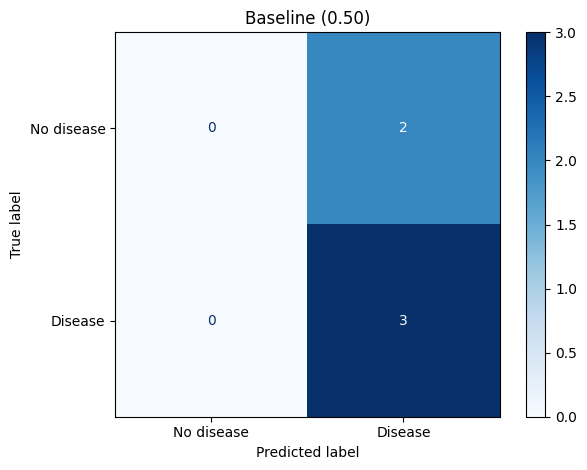

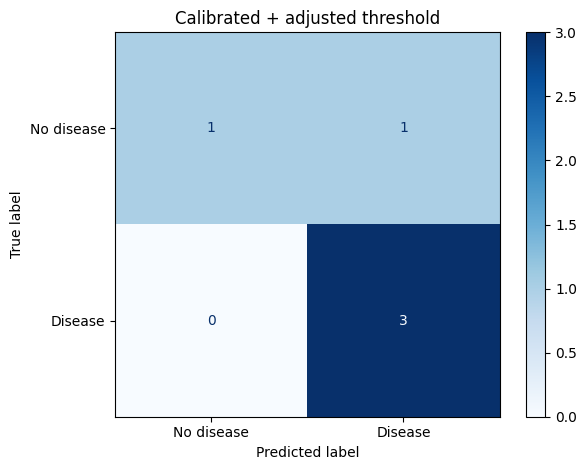

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Brier_Score
0,Baseline (0.50),0.6,0.60,1.0,0.7500,0.8333,0.1886
1,Calibrated + adjusted threshold,0.8,0.75,1.0,0.8571,0.8333,0.1988


In [18]:
test_baseline_probability = baseline_model.predict_proba(X_test)[:, 1]
test_calibrated_probability = calibrated_model.predict_proba(X_test)[:, 1]

test_predictions = {
    "Baseline (0.50)": (
        test_baseline_probability >= 0.50
    ).astype(int),

    "Calibrated + adjusted threshold": (
        test_calibrated_probability >= calibrated_threshold
    ).astype(int)
}

comparison_rows = []

for name, pred in test_predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(
            y_test,
            test_calibrated_probability
            if name == "Calibrated + adjusted threshold"
            else test_baseline_probability
        ),
        "Brier_Score": brier_score_loss(
            y_test,
            test_calibrated_probability
            if name == "Calibrated + adjusted threshold"
            else test_baseline_probability
        )
    })

    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No disease", "Disease"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(name)
    plt.tight_layout()
    plt.show()

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))


### Analyze misclassified examples and their characteristics by manually clustering error cases, detecting anomalies in feature distributions, and performing root-cause analysis to determine if specific subgroups are disproportionately affected.

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

y_pred = model.predict(X_test)

error_df = X_test.copy()
error_df["Actual"] = np.asarray(y_test)
error_df["Predicted"] = np.asarray(y_pred)

error_df["Error_Type"] = np.select(
    [
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

errors = error_df[
    error_df["Error_Type"] != "Correct"
].copy()

print("Total test samples:", len(error_df))
print("Correct predictions:",
      (error_df["Error_Type"] == "Correct").sum())
print("Total errors:", len(errors))
print("\nError type counts:")
print(errors["Error_Type"].value_counts())

display(errors)


Total test samples: 5
Correct predictions: 3
Total errors: 2

Error type counts:
Error_Type
False Positive    2
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Error_Type
22,56,1,2,130,256,1,0,142,1,0.6,1,1,1,0,1,False Positive
19,62,1,1,140,231,0,1,140,0,2.0,1,0,3,0,1,False Positive


Error_Type,Correct,False Positive
age,50.333,59.0
sex,0.333,1.0
cp,0.667,1.5
trestbps,136.667,135.0
chol,245.667,243.5
fbs,0.000,0.5
restecg,0.333,0.5
thalach,161.667,141.0
exang,0.000,0.5
oldpeak,1.300,1.3


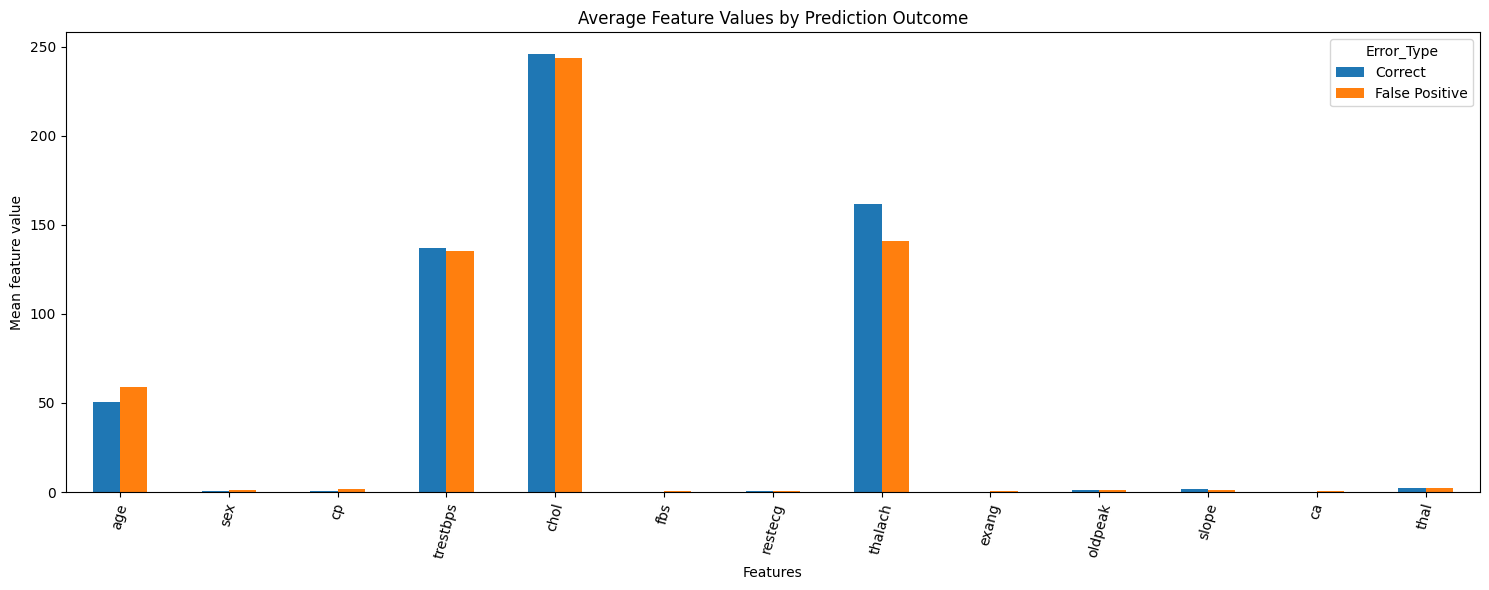

In [20]:
feature_cols = X_test.columns.tolist()

group_means = error_df.groupby(
    "Error_Type"
)[feature_cols].mean().T

display(group_means.round(3))

if len(group_means.columns) > 0:
    group_means.plot(
        kind="bar",
        figsize=(15, 6)
    )
    plt.title("Average Feature Values by Prediction Outcome")
    plt.xlabel("Features")
    plt.ylabel("Mean feature value")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.show()


Misclassified cases by cluster:


Actual      Predicted     
         count mean     count mean
Cluster                           
0            1  0.0         1  1.0
1            1  0.0         1  1.0

Error types in each cluster:


Error_Type,False Positive
Cluster,
0,1
1,1


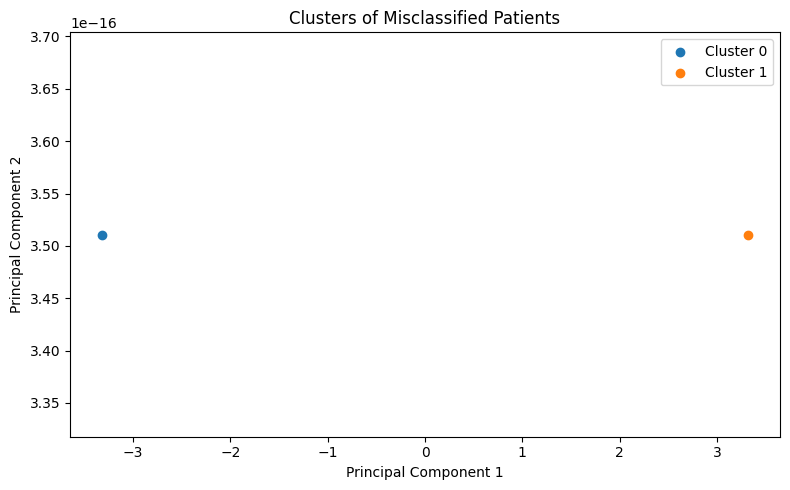

In [21]:

if len(errors) >= 2:
    X_errors = errors[feature_cols].copy()

    X_errors = X_errors.replace(
        [np.inf, -np.inf], np.nan
    )
    X_errors = X_errors.fillna(
        X_train.median(numeric_only=True)
    ).fillna(0)

    scaler = StandardScaler()
    X_errors_scaled = scaler.fit_transform(X_errors)

    n_clusters = min(3, len(errors))

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    errors["Cluster"] = kmeans.fit_predict(
        X_errors_scaled
    )

    print("Misclassified cases by cluster:")
    display(
        errors.groupby("Cluster")[
            ["Actual", "Predicted"]
        ].agg(["count", "mean"]).round(3)
    )

    print("Error types in each cluster:")
    display(pd.crosstab(
        errors["Cluster"],
        errors["Error_Type"]
    ))

    if X_errors_scaled.shape[1] >= 2:
        pca = PCA(n_components=2)
        coordinates = pca.fit_transform(X_errors_scaled)

        plt.figure(figsize=(8, 5))
        for cluster_id in sorted(errors["Cluster"].unique()):
            mask = errors["Cluster"].to_numpy() == cluster_id
            plt.scatter(
                coordinates[mask, 0],
                coordinates[mask, 1],
                label=f"Cluster {cluster_id}"
            )

        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.title("Clusters of Misclassified Patients")
        plt.legend()
        plt.tight_layout()
        plt.show()
else:
    print(
        "Not enough misclassified cases for clustering. "
        "At least 2 errors are required."
    )


In [22]:
X_train_clean = X_train[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)
X_test_clean = X_test[feature_cols].replace(
    [np.inf, -np.inf], np.nan
)

medians = X_train_clean.median(numeric_only=True)

X_train_clean = X_train_clean.fillna(medians).fillna(0)
X_test_clean = X_test_clean.fillna(medians).fillna(0)

anomaly_scaler = StandardScaler()
X_train_scaled = anomaly_scaler.fit_transform(X_train_clean)
X_test_scaled = anomaly_scaler.transform(X_test_clean)

iso = IsolationForest(
    contamination="auto",
    random_state=42
)

iso.fit(X_train_scaled)

error_df["Anomaly"] = np.where(
    iso.predict(X_test_scaled) == -1,
    "Anomaly",
    "Typical"
)

error_df["Is_Error"] = (
    error_df["Error_Type"] != "Correct"
).astype(int)

print("Anomaly status versus prediction outcome:")
display(pd.crosstab(
    error_df["Anomaly"],
    error_df["Error_Type"],
    margins=True
))

print("\nError rate by anomaly status:")
display(
    error_df.groupby("Anomaly")["Is_Error"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Samples",
        "sum": "Errors",
        "mean": "Error_Rate"
    })
    .round(3)
)


Anomaly status versus prediction outcome:


Error_Type,Correct,False Positive,All
Anomaly,,,
Anomaly,1,1,2
Typical,2,1,3
All,3,2,5



Error rate by anomaly status:


,Samples,Errors,Error_Rate
Anomaly,,,
Anomaly,2,1,0.500
Typical,3,1,0.333


In [23]:
subgroup_df = X_test.copy()
subgroup_df["Is_Error"] = (
    np.asarray(y_test) != np.asarray(y_pred)
).astype(int)

subgroup_results = []

for feature in feature_cols:
    values = subgroup_df[feature]

  
    unique_values = values.dropna().unique()

    if len(unique_values) <= 10:
        for value in sorted(unique_values, key=str):
            mask = values == value
            count = int(mask.sum())

            if count == 0:
                continue

            errors_count = int(
                subgroup_df.loc[mask, "Is_Error"].sum()
            )

            subgroup_results.append({
                "Feature": feature,
                "Group": str(value),
                "Samples": count,
                "Errors": errors_count,
                "Error_Rate": errors_count / count
            })

    else:
        try:
            bins = pd.qcut(
                values,
                q=3,
                labels=["Low", "Medium", "High"],
                duplicates="drop"
            )

            for group in bins.dropna().unique():
                mask = bins == group
                count = int(mask.sum())

                if count == 0:
                    continue

                errors_count = int(
                    subgroup_df.loc[mask, "Is_Error"].sum()
                )

                subgroup_results.append({
                    "Feature": feature,
                    "Group": str(group),
                    "Samples": count,
                    "Errors": errors_count,
                    "Error_Rate": errors_count / count
                })
        except ValueError:
            continue

subgroup_report = pd.DataFrame(subgroup_results)

if not subgroup_report.empty:
    min_group_size = 3

    reliable_size_view = subgroup_report[
        subgroup_report["Samples"] >= min_group_size
    ].copy()

    reliable_size_view = reliable_size_view.sort_values(
        ["Error_Rate", "Samples"],
        ascending=[False, False]
    )

    print("Overall test error rate:",
          round(subgroup_df["Is_Error"].mean(), 3))

    print("Subgroups with at least",
          min_group_size, "test samples:")

    display(reliable_size_view.head(20).round(3))

    if reliable_size_view.empty:
        print(
            "No subgroup has enough test samples. "
            "Use more evaluation data before drawing conclusions."
        )
else:
    print("No subgroup results could be calculated.")


Overall test error rate: 0.4
Subgroups with at least 3 test samples:


,Feature,Group,Samples,Errors,Error_Rate
5,sex,1,3,2,0.667
32,slope,1,3,2,0.667
7,cp,1,3,1,0.333
10,trestbps,140,3,1,0.333
18,restecg,0,3,1,0.333
16,fbs,0,4,1,0.250
25,exang,0,4,1,0.250
34,ca,0,4,1,0.250
37,thal,2,3,0,0.000


In [24]:
fp = error_df[error_df["Error_Type"] == "False Positive"]
fn = error_df[error_df["Error_Type"] == "False Negative"]

if len(fp) > 0 and len(fn) > 0:
    comparison = pd.DataFrame({
        "False_Positive_Mean": fp[feature_cols].mean(),
        "False_Negative_Mean": fn[feature_cols].mean()
    })

    comparison["Absolute_Difference"] = (
        comparison["False_Positive_Mean"]
        - comparison["False_Negative_Mean"]
    ).abs()

    display(
        comparison.sort_values(
            "Absolute_Difference",
            ascending=False
        ).round(3).head(15)
    )
else:
    print(
        "Both false positives and false negatives are needed "
        "for a direct comparison. Inspect the available error type."
    )


Both false positives and false negatives are needed for a direct comparison. Inspect the available error type.


### Identify bias in the model predictions by implementing fairness metrics such as disparate impact and equalized odds without using prebuilt fairness libraries, manually computing bias scores across demographic groups.

In [28]:
y_true = np.asarray(y_test).ravel()
y_pred = np.asarray(model.predict(X_test)).ravel()

fairness_df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred,
    "Group": X_test["sex"].to_numpy()
})

print("Group counts:")
display(fairness_df["Group"].value_counts())

print("Prediction results:")
display(fairness_df.head())


Group counts:


Group
1    3
0    2
Name: count, dtype: int64

Prediction results:


,Actual,Predicted,Group
0,1,1,0
1,1,1,0
2,0,1,1
3,1,1,1
4,0,1,1


In [29]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [30]:
sensitive_feature = "sex"

if sensitive_feature not in X_test.columns:
    raise ValueError(
        f"'{sensitive_feature}' was not found. "
        f"Available columns: {X_test.columns.tolist()}. "
        "Set sensitive_feature to an available demographic column."
    )

fairness_df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred,
    "Group": X_test[sensitive_feature].to_numpy()
})

print("Demographic group counts:")
display(fairness_df["Group"].value_counts(dropna=False))


Demographic group counts:


Group
1    3
0    2
Name: count, dtype: int64

In [31]:
reference_group = 0
comparison_group = 1

def calculate_group_metrics(data, group_value):
    group_data = data[data["Group"] == group_value]

    actual = group_data["Actual"].to_numpy()
    predicted = group_data["Predicted"].to_numpy()

    tp = np.sum((actual == 1) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fp = np.sum((actual == 0) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))

    def safe_divide(a, b):
        return a / b if b > 0 else np.nan

    return {
        "Group": group_value,
        "Samples": len(group_data),
        "Positive_Prediction_Rate": safe_divide(
            tp + fp, len(group_data)
        ),
        "TPR_Recall": safe_divide(tp, tp + fn),
        "FPR": safe_divide(fp, fp + tn),
        "Accuracy": safe_divide(tp + tn, len(group_data)),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

group_results = pd.DataFrame([
    calculate_group_metrics(fairness_df, reference_group),
    calculate_group_metrics(fairness_df, comparison_group)
]).set_index("Group")

print("Fairness metrics by demographic group:")
display(group_results.round(4))


Fairness metrics by demographic group:


,Samples,Positive_Prediction_Rate,TPR_Recall,FPR,Accuracy,TP,TN,FP,FN
Group,,,,,,,,,
0,2,1.0,1.0,NaN,1.0000,2,0,0,0
1,3,1.0,1.0,1.0,0.3333,1,0,2,0


In [32]:
reference_rate = group_results.loc[
    reference_group, "Positive_Prediction_Rate"
]
comparison_rate = group_results.loc[
    comparison_group, "Positive_Prediction_Rate"
]

if pd.isna(reference_rate) or pd.isna(comparison_rate):
    disparate_impact = np.nan
elif reference_rate == 0:
    disparate_impact = (
        np.inf if comparison_rate > 0
        else np.nan
    )
else:
    disparate_impact = comparison_rate / reference_rate

print("Reference group positive prediction rate:",
      round(reference_rate, 4)
      if pd.notna(reference_rate) else "Undefined")

print("Comparison group positive prediction rate:",
      round(comparison_rate, 4)
      if pd.notna(comparison_rate) else "Undefined")

print("Disparate Impact:", disparate_impact)

if pd.notna(disparate_impact):
    if 0.8 <= disparate_impact <= 1.25:
        print("Interpretation: Prediction rates are relatively similar.")
    else:
        print("Interpretation: Potential disparity detected.")
else:
    print("Interpretation: Ratio cannot be reliably calculated.")


Reference group positive prediction rate: 1.0
Comparison group positive prediction rate: 1.0
Disparate Impact: 1.0
Interpretation: Prediction rates are relatively similar.


In [33]:
tpr_reference = group_results.loc[
    reference_group, "TPR_Recall"
]
tpr_comparison = group_results.loc[
    comparison_group, "TPR_Recall"
]

fpr_reference = group_results.loc[
    reference_group, "FPR"
]
fpr_comparison = group_results.loc[
    comparison_group, "FPR"
]

tpr_gap = abs(tpr_comparison - tpr_reference)
fpr_gap = abs(fpr_comparison - fpr_reference)

print("True Positive Rate Gap:", round(tpr_gap, 4)
      if pd.notna(tpr_gap) else "Undefined")

print("False Positive Rate Gap:", round(fpr_gap, 4)
      if pd.notna(fpr_gap) else "Undefined")

if pd.notna(tpr_gap) and pd.notna(fpr_gap):
    equalized_odds_gap = max(tpr_gap, fpr_gap)
    print("Equalized Odds Gap:", round(equalized_odds_gap, 4))
else:
    equalized_odds_gap = np.nan
    print("Equalized Odds Gap cannot be fully calculated.")


True Positive Rate Gap: 0.0
False Positive Rate Gap: Undefined
Equalized Odds Gap cannot be fully calculated.


In [34]:
dp_difference = comparison_rate - reference_rate

print("Demographic Parity Difference:",
      round(dp_difference, 4)
      if pd.notna(dp_difference) else "Undefined")


Demographic Parity Difference: 0.0


### Apply bias mitigation techniques if necessary by implementing reweighting, adversarial debiasing, or preprocessing corrections, testing multiple bias-removal strategies and quantifying their effects on both fairness and performance.

In [35]:
sensitive_feature = "sex"

if sensitive_feature not in X_train.columns:
    raise ValueError(
        f"'{sensitive_feature}' is not in X_train. "
        "Check your original feature names and encoding."
    )

s_train = X_train[sensitive_feature].reset_index(drop=True)
s_test = X_test[sensitive_feature].reset_index(drop=True)

Xtr = X_train.reset_index(drop=True).copy()
Xte = X_test.reset_index(drop=True).copy()

ytr = pd.Series(np.asarray(y_train).ravel())
yte = pd.Series(np.asarray(y_test).ravel())

baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight=None
)

baseline_model.fit(Xtr, ytr)

print("Baseline model trained successfully.")


Baseline model trained successfully.


In [36]:
def evaluate_model(name, fitted_model, X_eval, y_eval, groups):
    actual = np.asarray(y_eval).ravel()
    predicted = fitted_model.predict(X_eval)

    if hasattr(fitted_model, "predict_proba"):
        probabilities = fitted_model.predict_proba(X_eval)[:, 1]
    else:
        probabilities = None

    result = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(actual, probabilities)
            if probabilities is not None and len(np.unique(actual)) == 2
            else np.nan
        )
    }

    group_metrics = []

    groups = np.asarray(groups)

    for group in pd.unique(groups):
        mask = groups == group
        a = actual[mask]
        p = predicted[mask]

        tp = np.sum((a == 1) & (p == 1))
        fp = np.sum((a == 0) & (p == 1))
        tn = np.sum((a == 0) & (p == 0))
        fn = np.sum((a == 1) & (p == 0))

        group_metrics.append({
            "Group": group,
            "Samples": int(mask.sum()),
            "Positive_Rate": np.mean(p == 1),
            "TPR": tp / (tp + fn) if tp + fn else np.nan,
            "FPR": fp / (fp + tn) if fp + tn else np.nan,
            "Recall": tp / (tp + fn) if tp + fn else np.nan
        })

    gm = pd.DataFrame(group_metrics).set_index("Group")

    result["Demographic_Parity_Gap"] = (
        gm["Positive_Rate"].max() - gm["Positive_Rate"].min()
    )

    result["Equalized_Odds_Gap"] = max(
        gm["TPR"].max() - gm["TPR"].min(),
        gm["FPR"].max() - gm["FPR"].min()
    )

    rates = gm["Positive_Rate"]
    if len(rates) == 2:
        result["Disparate_Impact"] = (
            rates.min() / rates.max() if rates.max() > 0 else np.nan
        )
    else:
        result["Disparate_Impact"] = np.nan

    return result, gm.reset_index()


baseline_result, baseline_groups = evaluate_model(
    "Baseline",
    baseline_model,
    Xte,
    yte,
    s_test
)

display(pd.DataFrame([baseline_result]).round(4))
display(baseline_groups.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Demographic_Parity_Gap,Equalized_Odds_Gap,Disparate_Impact
0,Baseline,0.6,0.6,1.0,0.75,0.8333,0.0,0.0,1.0


,Group,Samples,Positive_Rate,TPR,FPR,Recall
0,0,2,1.0,1.0,NaN,1.0
1,1,3,1.0,1.0,1.0,1.0


In [37]:
weight_data = pd.DataFrame({
    "Group": s_train,
    "Target": ytr
})

joint_counts = weight_data.groupby(
    ["Group", "Target"]
)["Target"].transform("size")

sample_weights = (
    len(weight_data) /
    (weight_data["Group"].nunique()
     * weight_data["Target"].nunique()
     * joint_counts)
).to_numpy()

sample_weights = sample_weights / sample_weights.mean()

reweighted_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight=None
)

reweighted_model.fit(
    Xtr,
    ytr,
    sample_weight=sample_weights
)

reweighted_result, reweighted_groups = evaluate_model(
    "Reweighting",
    reweighted_model,
    Xte,
    yte,
    s_test
)

display(pd.DataFrame([reweighted_result]).round(4))
display(reweighted_groups.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Demographic_Parity_Gap,Equalized_Odds_Gap,Disparate_Impact
0,Reweighting,0.6,0.6,1.0,0.75,0.8333,0.0,0.0,1.0


,Group,Samples,Positive_Rate,TPR,FPR,Recall
0,0,2,1.0,1.0,NaN,1.0
1,1,3,1.0,1.0,1.0,1.0


In [38]:
Xtr_no_sensitive = Xtr.drop(columns=[sensitive_feature])
Xte_no_sensitive = Xte.drop(columns=[sensitive_feature])

corrected_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight=None
)

corrected_model.fit(Xtr_no_sensitive, ytr)

corrected_result, corrected_groups = evaluate_model(
    "Sensitive Feature Removed",
    corrected_model,
    Xte_no_sensitive,
    yte,
    s_test
)

display(pd.DataFrame([corrected_result]).round(4))
display(corrected_groups.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Demographic_Parity_Gap,Equalized_Odds_Gap,Disparate_Impact
0,Sensitive Feature Removed,0.6,0.6,1.0,0.75,0.6667,0.0,0.0,1.0


,Group,Samples,Positive_Rate,TPR,FPR,Recall
0,0,2,1.0,1.0,NaN,1.0
1,1,3,1.0,1.0,1.0,1.0


In [39]:

results = pd.DataFrame([
    baseline_result,
    reweighted_result,
    corrected_result
])

baseline_values = results.iloc[0]

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "Demographic_Parity_Gap",
    "Equalized_Odds_Gap"
]:
    results[metric + "_Change"] = (
        results[metric] - baseline_values[metric]
    )


display(results.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Demographic_Parity_Gap,Equalized_Odds_Gap,Disparate_Impact,Accuracy_Change,Precision_Change,Recall_Change,F1_Change,ROC_AUC_Change,Demographic_Parity_Gap_Change,Equalized_Odds_Gap_Change
0,Baseline,0.6,0.6,1.0,0.75,0.8333,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0
1,Reweighting,0.6,0.6,1.0,0.75,0.8333,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0
2,Sensitive Feature Removed,0.6,0.6,1.0,0.75,0.6667,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.1667,0.0,0.0
